# Wireless Networking and Mobile Computing

### Prerequisites

This Jupyter Notebook has been tested with Visual Studio Code, running in a local Python environment (Python 3.8 or newer). Section 3 uses [Skyfield](https://rhodesmill.org/skyfield/), a standard Python library for satellite positions, and the helper file `Satellites/sat_tools.py` with a snapshot of the real orbits; keep the `Satellites` folder next to this notebook.

**Installs**

In [1]:
# --- Installs: ensure required packages are available ---
%pip install numpy matplotlib skyfield --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1. Transmitting GPS signals

#### 1.1 GPS orbit and frequencies

GPS satellites orbit the Earth at an altitude of about 20,200 km, completing two orbits per day. Their motion is carefully synchronized so that at least four satellites are visible from anywhere on Earth at all times. Each satellite continuously transmits radio signals toward Earth. Only the satellites transmit. Receivers on the ground are passive; they only listen to these signals. GPS uses several carrier frequencies on different radio bands:

| Band | Frequency (MHz) | Use | Notes |
|------|-----------------|------|-------|
| **L1** | 1575.42 | Civil | Used by all standard GPS receivers |
| **L2** | 1227.60 | Military (and dual-frequency civil) | Helps reduce atmospheric errors |
| **L5** | 1176.45 | Civil (aviation, safety-of-life) | Higher accuracy, modern systems |

These signals travel over 20,000 km, so they become very weak by the time they reach the ground, around -160 dBW, much weaker than background noise. However, GPS receivers can still detect them thanks to their unique coded structure and correlation processing, which allows the weak signals to stand out.

#### 1.2 Navigation message content

Each GPS signal includes a navigation message that carries important information about the satellite and the system. This message is transmitted at a very low data rate (50 b/s) and repeats continuously. It contains the **satellite status and health**, **precise time information**, **orbital parameters (ephemeris)** describing the exact path of the satellite, and **approximate orbit data (almanac)** the coarse information for all satellites. This message allows the receiver to compute where each satellite was when its signal was transmitted, which is essential for accurate positioning.

The almanac tells a receiver roughly where and when each satellite will be visible, but not with high precision. Each satellite broadcasts the full almanac for the whole constellation. A receiver uses it for initial acquisition (finding satellites quickly), but for accurate positioning it needs the ephemeris data (precise orbit info for a single satellite).

| **Aspect**       | **Almanac** (approximate orbit data)                                       | **Ephemeris** (precise orbit data)             |
| ---------------- | -------------------------------------------------------------------------- | ---------------------------------------------- |
| **Scope**        | Info for *all satellites* in the constellation                             | Info for *one satellite* only                  |
| **Accuracy**     | Coarse (km-level) orbit + clock info                                       | Precise (meter-level) orbit + clock info       |
| **Size**         | Small dataset (~1 KB)                                                      | Larger dataset (~1 to 2 KB per satellite)         |
| **Validity**     | Days to weeks (stable over time)                                           | A few hours (must be refreshed often)          |
| **Transmission** | Sent by every satellite, for all satellites                                | Sent by each satellite, only for itself        |
| **Use**          | Helps receiver know *which satellites* to search for, and where in the sky | Needed for *accurate positioning* calculations |
| **Acquisition**  | Takes ~12.5 minutes to receive full set                                    | Takes ~30 seconds per satellite (good signal)  |

#### 1.3 PRN codes and signal modulation

Each GPS satellite uses a unique **Pseudo-Random Noise (PRN)** code to identify its signal. The main civil code is the **C/A (Coarse/Acquisition)** code, transmitted on the L1 frequency. It consists of 1,023 binary chips (+1 and -1) repeating every millisecond. Though it looks random, it is deterministic and known, so receivers can generate the same code locally.

Each satellite’s distinct PRN code allows all satellites to transmit on the same frequency using **Code Division Multiple Access (CDMA)**.
The transmitted GPS signal combines:

* the **carrier wave** (e.g., 1575.42 MHz for L1),
* the **PRN code**, which spreads the spectrum, and
* the **navigation message**, which carries timing and orbit data.

At the receiver, the signal is **correlated** with a locally generated PRN code. When alignment occurs, a sharp **correlation peak** reveals the signal delay, which gives the distance to that satellite.

#### 1.4 Demonstration: Spreading and Despreading in Slow Motion

Below we simulate how a GPS receiver identifies a satellite signal, slowed down so that every step is visible: 100 chips per second instead of 1.023 million, and a carrier of 100 Hz instead of 1.57542 GHz. The code is 10 chips long and repeats once per message symbol (GPS: 1,023 chips, repeating every millisecond, 20 times per navigation bit). Section 2 then does the same at the real rates.

**Setup**

In [2]:
# --- Imports and Parameters ---
import numpy as np
import matplotlib.pyplot as plt

# Parameters (slow motion)
num_symbols = 6
samples_per_symbol = 1000
samples_per_chip = 100
chips_per_code = samples_per_symbol // samples_per_chip     # the code repeats once per symbol
fc = 100                                                    # carrier frequency (Hz)
fs = 10000                                                  # sample rate (Hz)
T_total = num_symbols * samples_per_symbol / fs
t = np.arange(0, T_total, 1/fs)
Rc = fs / samples_per_chip                                  # chip rate (chips per second)
np.random.seed(0)

# Plot style
axes_facecolor = (0.1, 0.1, 0.15)
line_color = {
    "message": "magenta",
    "prn": "deepskyblue",
    "spread": "red",
    "rx": "yellow",
    "baseband": "limegreen",
    "corr": "orange"
}

**Transmitter generates message and PRN Code**

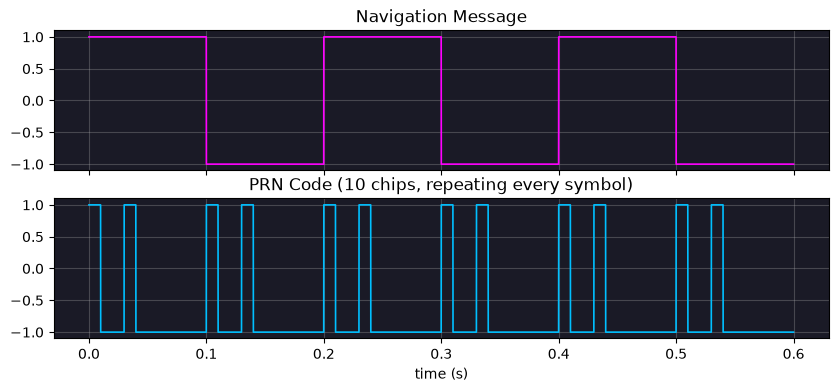

In [3]:
# --- Message and PRN code ---
msg_symbols = np.array([1 if i % 2 == 0 else -1 for i in range(num_symbols)])
message = np.repeat(msg_symbols, samples_per_symbol)[:len(t)]

prn_chips = np.random.choice([1, -1], size=chips_per_code)                   # one code period
prn = np.tile(np.repeat(prn_chips, samples_per_chip), num_symbols)[:len(t)]   # repeated for every symbol

fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
plots = [
    (message, "Navigation Message", line_color["message"]),
    (prn, "PRN Code (10 chips, repeating every symbol)", line_color["prn"])
]
for ax, (data, title, color) in zip(axes, plots):
    ax.plot(t, data, color=color, lw=1.2)
    ax.set_title(title, pad=6)
    ax.set_facecolor(axes_facecolor)
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("time (s)")
plt.show()

**Transmitter spreads the message and modulates onto carrier**

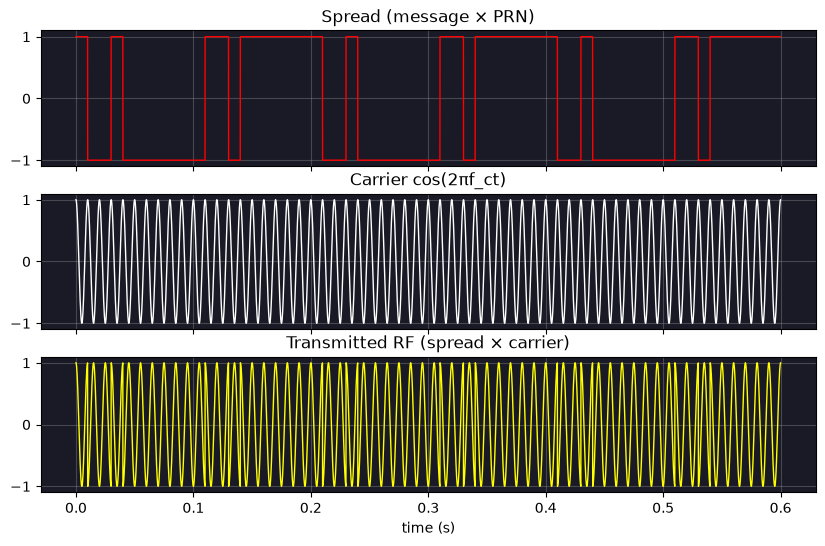

In [4]:
# --- Spread & Modulate ---
spread = message * prn
carrier = np.cos(2*np.pi*fc*t)
tx = spread * carrier

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
plots = [
    (spread, "Spread (message × PRN)", line_color["spread"]),
    (carrier, "Carrier cos(2πf_ct)", "white"),
    (tx, "Transmitted RF (spread × carrier)", line_color["rx"]),
]
for ax, (sig, label, color) in zip(axes, plots):
    ax.plot(t, sig, color=color, lw=1.0)
    ax.set_title(label, pad=6)
    ax.set_facecolor(axes_facecolor)
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("time (s)")
plt.show()

**Propagation delays, adds noise and phase effects**

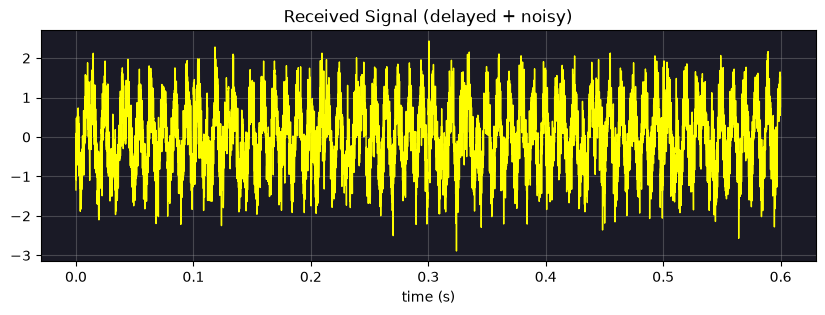

In [5]:
# --- Simulate signal propagation ---
snr_db = 3.0
code_phase_offset = 12          # delay in samples
carrier_phase = 0.4
freq_offset_hz = 0.0

prn_rx = np.roll(prn, code_phase_offset)
spread_rx = message * prn_rx
carrier_ch = np.cos(2*np.pi*(fc + freq_offset_hz)*t + carrier_phase)
tx_offset = spread_rx * carrier_ch

def add_awgn(x, snr_db):
    sig_power = np.mean(x**2)
    snr_lin = 10**(snr_db/10)
    noise_power = sig_power / snr_lin
    noise = np.sqrt(noise_power) * np.random.randn(*x.shape)
    return x + noise

rx = add_awgn(tx_offset, snr_db)

plt.figure(figsize=(10, 3))
plt.plot(t, rx, color=line_color["rx"], lw=1)
plt.title("Received Signal (delayed + noisy)", pad=6)
plt.xlabel("time (s)")
plt.grid(True, alpha=0.3)
plt.gca().set_facecolor(axes_facecolor)
plt.show()

**Receiver removes carrier and despreads the signal**

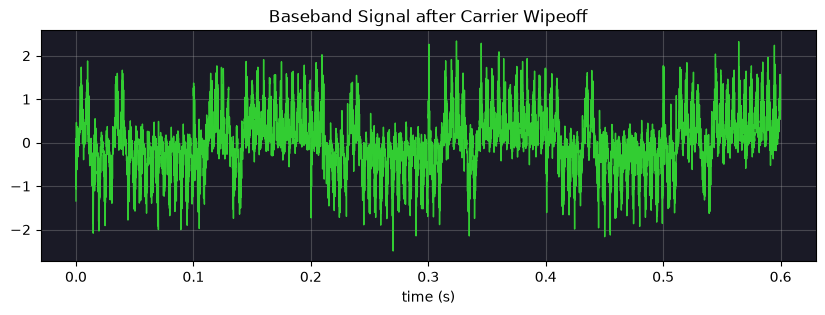

In [6]:
# ---  Demodulate & Despread ---
lo = np.cos(2*np.pi*fc*t)
baseband = rx * lo

plt.figure(figsize=(10, 3))
plt.plot(t, baseband, color=line_color["baseband"], lw=1)
plt.title("Baseband Signal after Carrier Wipeoff", pad=6)
plt.xlabel("time (s)")
plt.grid(True, alpha=0.3)
plt.gca().set_facecolor(axes_facecolor)
plt.show()

**Receiver correlates with PRN to find delay and recover message**

The receiver does not know the delay, so it tries **every code phase in one full code period** (here 1,000 samples) and keeps the one where its local copy matches best. For each trial it correlates every symbol separately and adds the magnitudes: the message bit may flip between symbols, which would cancel a plain sum.

Estimated code phase: 12 samples = 0.12 chips (true delay: 12 samples)
Time delay: 1.2 ms in this slow-motion demo
At the real GPS chip rate, 0.12 chips would be 0.117 us, or 35 m of range



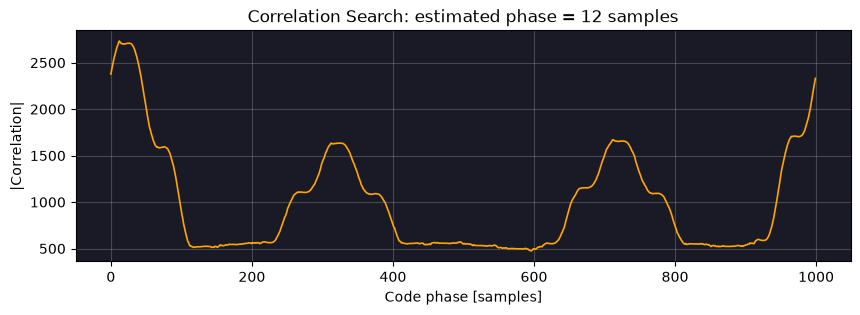

In [7]:
# --- Correlate over one full code period ---
code_period = samples_per_symbol                 # number of possible code phases
metrics = np.zeros(code_period)

for tau in range(code_period):
    prn_hyp = np.roll(prn, tau)
    per_symbol = (baseband * prn_hyp).reshape(num_symbols, samples_per_symbol).sum(axis=1)
    metrics[tau] = np.sum(np.abs(per_symbol))    # non-coherent: magnitudes, so bit flips do not cancel

est_code_phase = int(np.argmax(metrics))

# Convert the code phase to chips and time: samples / sample rate (not / chip rate)
est_chips = est_code_phase / samples_per_chip
delta_t = est_code_phase / fs                    # seconds

print(f"Estimated code phase: {est_code_phase} samples = {est_chips:.2f} chips (true delay: {code_phase_offset} samples)")
print(f"Time delay: {delta_t * 1e3:.1f} ms in this slow-motion demo")
print(f"At the real GPS chip rate, {est_chips:.2f} chips would be {est_chips / 1.023e6 * 1e6:.3f} us, "
      f"or {est_chips / 1.023e6 * 3e8:.0f} m of range\n")

# Despread and recover message
prn_aligned = np.roll(prn, est_code_phase)
despread = baseband * prn_aligned
despread_reshaped = despread[:num_symbols*samples_per_symbol].reshape(num_symbols, samples_per_symbol)
symbol_sums = np.sum(despread_reshaped, axis=1)
msg_hat = np.sign(symbol_sums)
msg_hat[msg_hat == 0] = 1
ber = np.mean(msg_hat != msg_symbols)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(np.arange(code_period), metrics, color=line_color["corr"], lw=1.2)
ax.set_title(f"Correlation Search: estimated phase = {est_code_phase} samples", pad=6)
ax.set_xlabel("Code phase [samples]")
ax.set_ylabel("|Correlation|")
ax.set_facecolor(axes_facecolor)
ax.grid(True, alpha=0.3)
plt.show()

##### 1.4.1 Summary Plot

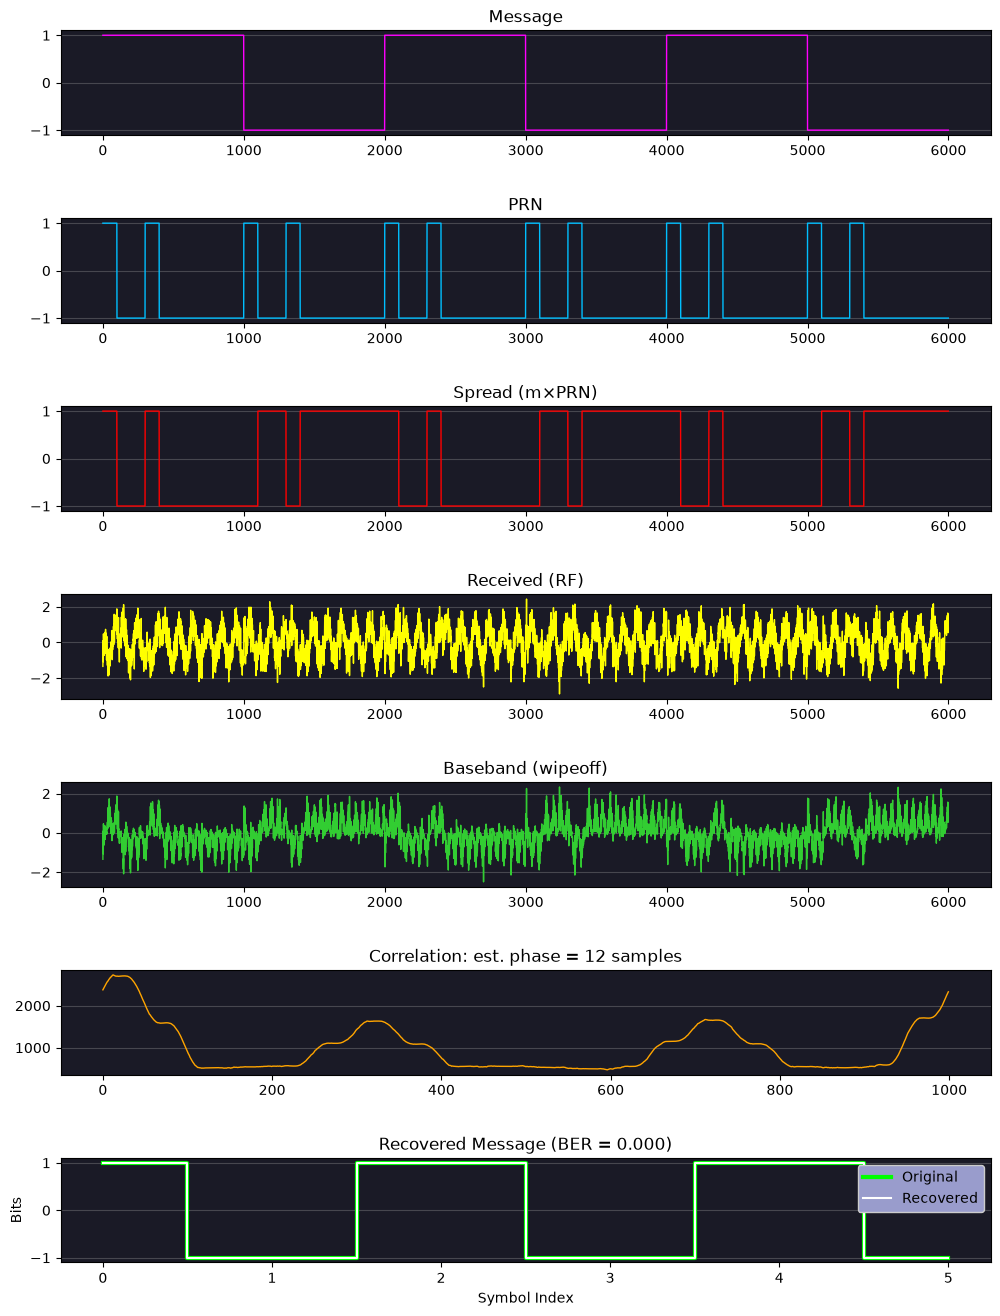

In [8]:
# --- Combined visualization: full transmitter-receiver chain ---
fig, axes = plt.subplots(7, 1, figsize=(12, 16), sharex=False, gridspec_kw={"hspace": 0.8})

def beautify(ax):
    ax.grid(True, axis='y', alpha=0.3)
    ax.set_facecolor(axes_facecolor)

plots = [
    (message, "Message", line_color["message"]),
    (prn, "PRN", line_color["prn"]),
    (spread, "Spread (m×PRN)", line_color["spread"]),
    (rx, "Received (RF)", line_color["rx"]),
    (baseband, "Baseband (wipeoff)", line_color["baseband"]),
    (metrics, f"Correlation: est. phase = {est_code_phase} samples", line_color["corr"]),
]
for i, (data, label, color) in enumerate(plots):
    axes[i].plot(data, color=color, lw=1)
    axes[i].set_title(label, loc="center", pad=6)
    beautify(axes[i])

n = np.arange(num_symbols)
axes[6].step(n, msg_symbols, where='mid', lw=3, color="lime", label="Original")
axes[6].step(n, msg_hat, where='mid', lw=1.5, color="white", label="Recovered")
axes[6].set_title(f"Recovered Message (BER = {ber:.3f})", pad=6)
axes[6].set_xlabel("Symbol Index")
axes[6].set_ylabel("Bits")
axes[6].legend(fancybox=True, framealpha=1, facecolor=(0.6, 0.61, 0.8))
beautify(axes[6])
plt.show()

**Explanation:**

* Each **chip** of the real C/A code lasts about **1 µs**: 1,023 chips at 1.023 Mcps repeat every 1 ms. The demo above runs about 10,000 times slower.
* The **BPSK-modulated** signal is a sine wave whose phase flips according to the PRN sequence.
* The **correlation peak** appears when the locally generated code aligns with the received one. Its position is the **code phase**, which gives the travel time of the signal: delay = code phase in samples / sample rate.

> Even with weak and noisy signals, correlation lets the receiver identify the satellite's unique PRN pattern.

### 2. A Real GPS Signal Below the Noise

A GPS signal arrives at about -130 dBm, far below the thermal noise in its 2 MHz bandwidth (about -111 dBm). This section shows how a receiver still finds it, with the real C/A code and real rates.

#### 2.1 The C/A Code

Each satellite's code comes from two 10-bit shift registers (G1 and G2). The satellite's PRN number selects two taps of G2. The check below compares the first 10 chips with the values published in the GPS interface specification (IS-GPS-200, in octal).

In [9]:
# --- The GPS C/A code generator ---
CHIP_RATE = 1.023e6     # chips per second
CODE_LEN = 1023         # chips per code period (1 ms)
C = 299_792_458.0       # speed of light (m/s)

G2_TAPS = {1: (2, 6), 2: (3, 7), 3: (4, 8), 4: (5, 9), 5: (1, 9), 6: (2, 10), 7: (1, 8), 8: (2, 9), 9: (3, 10),
           10: (2, 3), 11: (3, 4), 12: (5, 6), 13: (6, 7), 14: (7, 8), 15: (8, 9), 16: (9, 10), 17: (1, 4),
           18: (2, 5), 19: (3, 6), 20: (4, 7), 21: (5, 8), 22: (6, 9), 23: (1, 3), 24: (4, 6), 25: (5, 7),
           26: (6, 8), 27: (7, 9), 28: (8, 10), 29: (1, 6), 30: (2, 7), 31: (3, 8), 32: (4, 9)}

def ca_code(prn):
    """The 1,023 chips (0/1) of the C/A code of one GPS satellite."""
    g1, g2 = [1] * 10, [1] * 10
    a, b = G2_TAPS[prn]
    chips = []
    for _ in range(CODE_LEN):
        chips.append(g1[9] ^ g2[a - 1] ^ g2[b - 1])
        g1 = [g1[2] ^ g1[9]] + g1[:9]
        g2 = [g2[1] ^ g2[2] ^ g2[5] ^ g2[7] ^ g2[8] ^ g2[9]] + g2[:9]
    return np.array(chips)

for prn, octal in ((1, "1440"), (2, "1620"), (3, "1710"), (19, "1633")):
    first = "".join(map(str, ca_code(prn)[:10]))
    print(f"PRN {prn:2d}: first 10 chips {first} = octal {int(first, 2):o} (specification: {octal})")

# Two different codes barely correlate; a code correlates fully only with itself, aligned
c1, c2 = 1 - 2 * ca_code(1), 1 - 2 * ca_code(2)
print(f"\ncorrelation PRN 1 with itself: {np.dot(c1, c1)}, with PRN 2: {np.dot(c1, c2)}, "
      f"with itself shifted by 1 chip: {np.dot(c1, np.roll(c1, 1))}")

PRN  1: first 10 chips 1100100000 = octal 1440 (specification: 1440)
PRN  2: first 10 chips 1110010000 = octal 1620 (specification: 1620)
PRN  3: first 10 chips 1111001000 = octal 1710 (specification: 1710)
PRN 19: first 10 chips 1110011011 = octal 1633 (specification: 1633)

correlation PRN 1 with itself: 1023, with PRN 2: -1, with itself shifted by 1 chip: -1


#### 2.2 Your Satellite

Your matriculation number picks the satellite (PRN) you search for and its code phase: where in its 1,023-chip code the signal arrives.

In [10]:
# --- Declarations: editable variables for students ---
MATRICULATION = "21-715-917"     # <-- Change this. Your matriculation number

import hashlib, re
digits = re.sub(r"\D", "", MATRICULATION)
seed = int(hashlib.sha256(digits.encode()).hexdigest()[:8], 16)
PRN = 1 + seed % 32
TRUE_CODE_PHASE = (seed // 32 % 1_023_000) / 1000     # chips (hidden from the receiver)
rng = np.random.default_rng(seed)
code = 1 - 2 * ca_code(PRN)                           # chips as +1 / -1
print(f"You search for PRN {PRN}.")

You search for PRN 1.


#### 2.3 Sampling the Signal

The receiver samples the signal at $f_s = 4.0$ MHz, which is **not** a multiple of the chip rate (3.91 samples per chip). The sample instants then slide along the chips, so the code phase can be measured finer than a chip, and the sampling clock does not lock onto the code.

The receiver's front end has removed the carrier (as in 1.4) and the Doppler shift (we assume it is known). Each sample is a real number carrying noise from a 2 MHz band, so the SNR per sample is $\text{SNR} = C/N_0 - 10\log_{10}(2\ \text{MHz}) = C/N_0 - 63$ dB, where $C/N_0$ is the carrier-to-noise density a receiver reports: about 45 dB-Hz outdoors, 25 dB-Hz or less indoors.

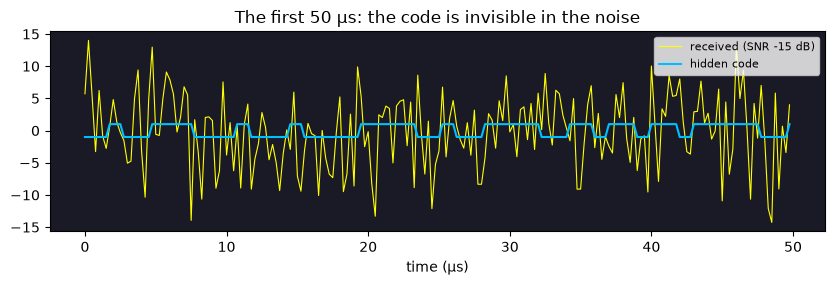

In [11]:
FS = 4.0e6                  # sample rate (Hz)
N1 = int(FS * 1e-3)         # samples per 1 ms code period

def sampled_code(n_ms, code_phase_chips=0.0):
    """n_ms milliseconds of the code, delayed by code_phase_chips, sampled at FS."""
    t = np.arange(n_ms * N1) / FS
    return code[np.floor((t * CHIP_RATE - code_phase_chips) % CODE_LEN).astype(int)]

def received(snr_db, n_ms):
    """What the antenna delivers: your satellite's code, delayed, plus noise."""
    return sampled_code(n_ms, TRUE_CODE_PHASE) + rng.normal(0, np.sqrt(10 ** (-snr_db / 10)), n_ms * N1)

x = received(snr_db=-15, n_ms=1)
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.plot(np.arange(200) / FS * 1e6, x[:200], color=line_color["rx"], lw=0.8, label="received (SNR -15 dB)")
ax.plot(np.arange(200) / FS * 1e6, sampled_code(1, TRUE_CODE_PHASE)[:200], color=line_color["prn"], lw=1.5, label="hidden code")
ax.set(xlabel="time (µs)", title="The first 50 µs: the code is invisible in the noise")
ax.set_facecolor(axes_facecolor)
ax.legend(loc="upper right", fontsize=8)
plt.show()

#### 2.4 Searching All Code Phases at Once

Trying 4,000 code phases one by one (as in 1.4) is slow. A circular correlation computes all of them at once with the FFT:

$$
r[k] = \mathcal{F}^{-1}\left\{\mathcal{F}\{x\} \cdot \mathcal{F}\{c\}^*\right\}[k].
$$

The peak's position $k$ is the code phase in samples. Converting it: time = $k / f_s$, chips = time × chip rate, range = time × $c$. The code repeats every millisecond, so the receiver only learns the range **modulo** 1 ms × $c$ ≈ 299.8 km: the whole milliseconds (the satellites are 67 to 86 ms away) come from the navigation message or from an approximate position.

PRN 1: peak at code phase 2654 samples
   = 663.50 µs = 678.76 chips (true: 678.79 chips)
   = 198.91 km of range, modulo 299.8 km


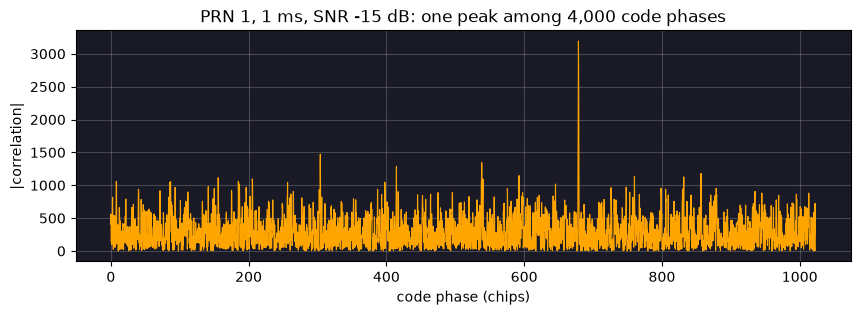

In [12]:
local_fft = np.conj(np.fft.fft(sampled_code(1)))       # the receiver's copy of the code, at code phase 0

def correlate(x, n_ms):
    """Correlation for all N1 code phases, summed coherently over n_ms code periods."""
    acc = np.zeros(N1)
    for m in range(n_ms):
        acc += np.real(np.fft.ifft(np.fft.fft(x[m * N1:(m + 1) * N1]) * local_fft))
    return acc

corr = correlate(x, 1)
k = int(np.argmax(np.abs(corr)))
delay_s = k / FS
print(f"PRN {PRN}: peak at code phase {k} samples")
print(f"   = {delay_s * 1e6:.2f} µs = {delay_s * CHIP_RATE:.2f} chips (true: {TRUE_CODE_PHASE:.2f} chips)")
print(f"   = {delay_s * C / 1e3:.2f} km of range, modulo {1e-3 * C / 1e3:.1f} km")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(np.arange(N1) / FS * CHIP_RATE, np.abs(corr), color=line_color["corr"], lw=0.8)
ax.set(xlabel="code phase (chips)", ylabel="|correlation|", title=f"PRN {PRN}, 1 ms, SNR -15 dB: one peak among 4,000 code phases")
ax.set_facecolor(axes_facecolor)
ax.grid(True, alpha=0.3)
plt.show()

#### 2.5 When Is a Peak a Satellite?

There is always a highest point, even in pure noise. The receiver declares a satellite only if the peak stands out: here, if the peak's power divided by the mean power of all code phases exceeds a **threshold**. The threshold is set from noise alone so that a false alarm happens in only 1 of 1,000 searches.

#### 2.6 Processing Gain: Why Integration Wins

Correlating $N$ samples adds the signal $N$ times coherently, but the noise only $\sqrt{N}$ times in amplitude: the SNR grows by $10\log_{10} N$, the **processing gain**. One millisecond at 4 MHz gives 4,000 samples, about 36 dB. Summing 10 code periods coherently gives 10 dB more (as long as the navigation bit, which can flip every 20 ms, and the Doppler stay constant). The plot shows how often the receiver finds your satellite at the right code phase, against the SNR per sample.

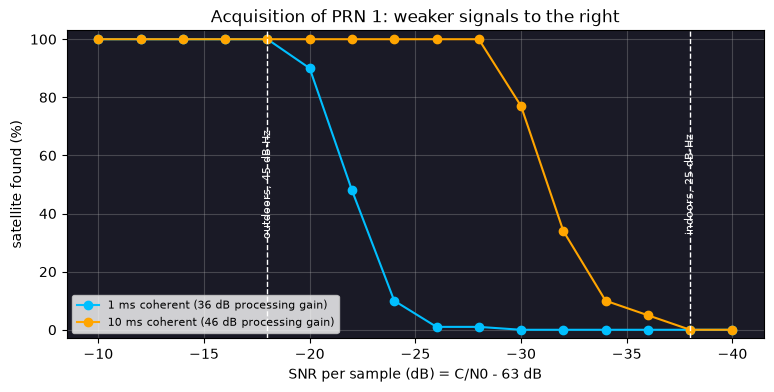

 1 ms: found in at least 90 % of the searches down to -20 dB
10 ms: found in at least 90 % of the searches down to -28 dB


In [13]:
def peak_metric(corr):
    p = np.abs(corr) ** 2
    return p.max() / p.mean()

# Threshold from noise alone: false alarm in 1 of 1,000 searches
THRESHOLD = {n: np.quantile([peak_metric(correlate(rng.normal(0, 1, n * N1), n)) for _ in range(300)], 0.999)
             for n in (1, 10)}

def acquisition_rate(snr_db, n_ms, trials=100):
    found = 0
    for _ in range(trials):
        c = correlate(received(snr_db, n_ms), n_ms)
        err = abs(np.argmax(np.abs(c)) / FS * CHIP_RATE - TRUE_CODE_PHASE)
        found += (peak_metric(c) > THRESHOLD[n_ms]) and min(err, CODE_LEN - err) < 0.5
    return found / trials

SNRS_DB = np.arange(-10, -42, -2)        # <-- Change this. SNR per sample (dB)
rates = {n: [acquisition_rate(s, n) for s in SNRS_DB] for n in (1, 10)}

fig, ax = plt.subplots(figsize=(9, 4))
for n, col in ((1, "deepskyblue"), (10, "orange")):
    ax.plot(SNRS_DB, np.array(rates[n]) * 100, "o-", color=col, label=f"{n} ms coherent ({10 * np.log10(n * N1):.0f} dB processing gain)")
for cn0, label in ((45, "outdoors, 45 dB-Hz"), (25, "indoors, 25 dB-Hz")):
    ax.axvline(cn0 - 63, color="white", ls="--", lw=1)
    ax.text(cn0 - 63 + 0.3, 50, label, color="white", rotation=90, va="center", fontsize=8)
ax.set(xlabel="SNR per sample (dB) = C/N0 - 63 dB", ylabel="satellite found (%)", ylim=(-3, 103))
ax.invert_xaxis()
ax.set_title(f"Acquisition of PRN {PRN}: weaker signals to the right")
ax.set_facecolor(axes_facecolor)
ax.grid(True, alpha=0.3)
ax.legend(loc="lower left", fontsize=8)
plt.show()
for n in (1, 10):
    ok = SNRS_DB[np.array(rates[n]) >= 0.9]
    print(f"{n:2d} ms: found in at least 90 % of the searches down to {ok.min() if len(ok) else 'none'} dB")

### 3. Navigation Satellites in a Street

A receiver needs at least four satellites: three for its position and one for the error of its clock. How well it fixes its position depends on how many satellites it sees, and on their geometry. Satellites spread over the whole sky give a sharp position; satellites bunched in one direction give a blurred one. The dilution of precision (DOP) measures this: the position error is about the DOP times the error of a single range measurement, which is about 3 m for a phone with a clear view of the sky. PDOP is the DOP of the 3D position, HDOP that of the horizontal position.

Phones use the four global systems: GPS (United States), Galileo (European Union), GLONASS (Russia) and BeiDou (China). The positions below come from a snapshot of their real orbits.

In a street, a phone only sees the strip of sky between the buildings. For a straight street of width $w$ with walls of height $h$, a satellite is hidden if its elevation is below

$$
\epsilon_{\text{wall}} = \arctan\left(\frac{h \, |\sin\alpha|}{w/2}\right),
$$

where $\alpha$ is the azimuth of the satellite relative to the direction of the street. Along the street, the sky is open; across it, the walls hide everything below $\arctan(2h/w)$.

Pick a narrow street you know and a time. On map.geo.admin.ch or any other map, a right-click shows the coordinates of a point. Enter the coordinates, the time in Swiss local time, and the width, wall height and direction of the street.

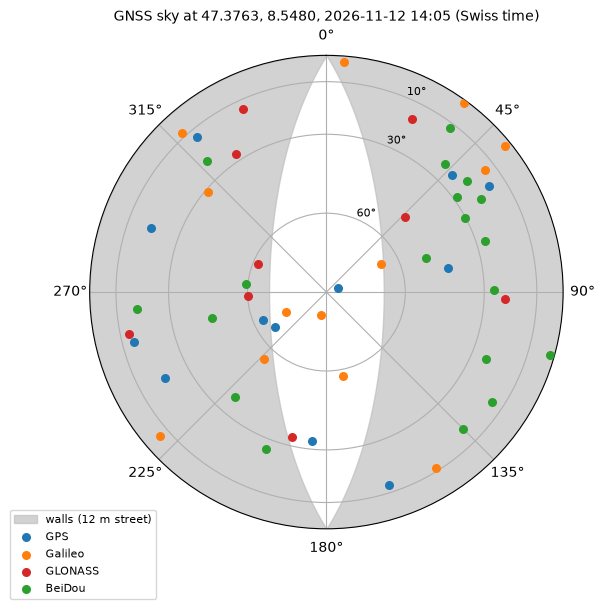

where                             systems                              sats   PDOP   HDOP  ~accuracy
open sky                          GPS + Galileo                          20    1.0    0.6      1.8 m
open sky                          GPS + Galileo + GLONASS + BeiDou       47    0.7    0.4      1.1 m
street 12 m wide, 15 m walls      GPS + Galileo                           7    6.6    3.4     10.3 m
street 12 m wide, 15 m walls      GPS + Galileo + GLONASS + BeiDou        8    6.1    3.4     10.1 m
(satellites above 10 deg and above the walls; accuracy ~ HDOP x 3 m, geometry only: reflections in a street add more)


In [14]:
from Satellites.sat_tools import swiss_time_to_utc, gnss_sky, plot_sky, sky_table, street_sweep

# --- Your street ---
LAT, LON  = 47.3763, 8.5480                  # <-- Change this. The street (degrees)
WHEN      = "2026-11-12 14:05"               # <-- Change this. Swiss local time
STREET    = dict(width_m=12, height_m=15,    # <-- Change this. Street width and wall height (m)
                 direction_deg=0)            # <-- Change this. Direction of the street (0 = north-south, 90 = east-west)

sky = gnss_sky(LAT, LON, swiss_time_to_utc(WHEN))
plot_sky(sky, STREET, title=f"GNSS sky at {LAT:.4f}, {LON:.4f}, {WHEN} (Swiss time)")
rows = sky_table(sky, STREET)

#### 3.1 A Street Over a Whole Day

The satellites move, so a single moment can be lucky or unlucky. The sweep below repeats the calculation every 10 minutes over one day. It shows how much of the time a phone in the street still sees at least four satellites, and how good the geometry is, for different street widths.

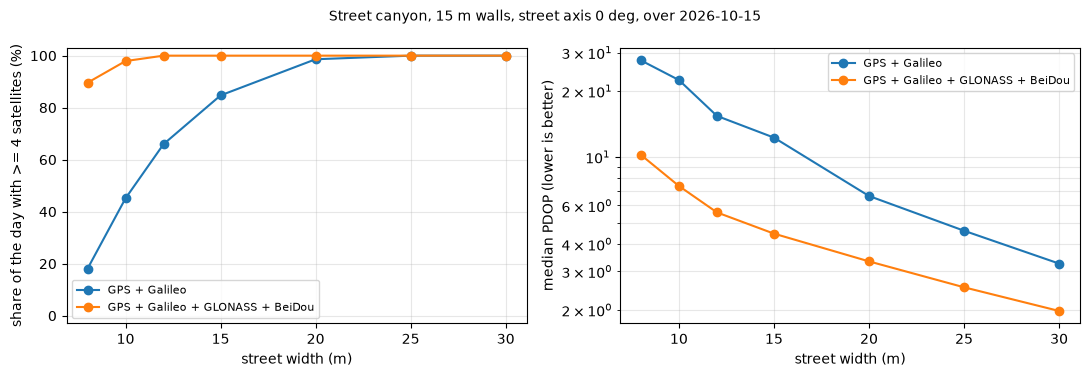

 width                     GPS + Galileo  GPS + Galileo + GLONASS + BeiDou
    8m           18 % fix, PDOP   27.6           90 % fix, PDOP   10.2
   10m           45 % fix, PDOP   22.5           98 % fix, PDOP    7.4
   12m           66 % fix, PDOP   15.4          100 % fix, PDOP    5.6
   15m           85 % fix, PDOP   12.3          100 % fix, PDOP    4.5
   20m           99 % fix, PDOP    6.6          100 % fix, PDOP    3.3
   25m          100 % fix, PDOP    4.6          100 % fix, PDOP    2.5
   30m          100 % fix, PDOP    3.3          100 % fix, PDOP    2.0


In [15]:
sweep = street_sweep(LAT, LON, height_m=STREET["height_m"], direction_deg=STREET["direction_deg"])